# Dogecoin Price — Lag-Feature Regression

I did Bitcoin with an LSTM in the neighboring notebook. DOGE feels like a different beast — it moves on tweets, not fundamentals, and an LSTM on the daily close would be the same kind of "predict yesterday with extra steps" that I got on BTC. So this is much simpler: lag features + gradient boosting + linear regression, with the explicit understanding that whatever number comes out is going to be dominated by lag-1.

I'm including this one for honesty as much as anything. "I tried it on DOGE and the model basically learned to copy yesterday's price" is more interesting than a Medium post claiming 95% accuracy.


In [1]:
# !pip install yfinance scikit-learn xgboost -q
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)


In [2]:
doge = yf.download("DOGE-USD", period="3y", progress=False, auto_adjust=True)
doge = doge[["Close", "Volume"]].dropna()
doge.columns = ["close", "volume"]
print(f"DOGE-USD: {len(doge)} rows | {doge.index.min().date()} -> {doge.index.max().date()}")
print(f"Current price: ${doge['close'].iloc[-1]:.4f}  (yes, it's still measured in fractions of a cent)")
doge.tail(3)


DOGE-USD: 1096 rows | 2023-05-14 -> 2026-05-14
Current price: $0.1131  (yes, it's still measured in fractions of a cent)


,close,volume
Date,,
2026-05-11,0.111275,1467112252
2026-05-12,0.110016,1220750077
2026-05-14,0.113110,2131952128


## Feature engineering: just lags and rolling stats

No clever feature crosses, no sentiment scrape. The point of this notebook is to ask "how much of DOGE's price tomorrow is in its price history alone" and the answer is "mostly yesterday's price, the rest is noise".


In [3]:
df = doge.copy()
df["ret"] = df["close"].pct_change()

for k in [1, 2, 3, 7, 14]:
    df[f"lag_close_{k}"] = df["close"].shift(k)
    df[f"lag_ret_{k}"]   = df["ret"].shift(k)

df["roll7_mean"]  = df["close"].rolling(7).mean()
df["roll7_std"]   = df["close"].rolling(7).std()
df["roll30_mean"] = df["close"].rolling(30).mean()
df["vol_z7"]      = (df["volume"] - df["volume"].rolling(7).mean()) / df["volume"].rolling(7).std()

df = df.dropna()
feature_cols = [c for c in df.columns if c not in ("close", "ret", "volume")]
print(f"Features: {len(feature_cols)}  |  Samples after dropna: {len(df)}")


Features: 14  |  Samples after dropna: 1067


In [4]:
# chronological split, last 90 days held out
split = len(df) - 90
X_train = df[feature_cols].iloc[:split]
X_test  = df[feature_cols].iloc[split:]
y_train = df["close"].iloc[:split]
y_test  = df["close"].iloc[split:]

models = {
    "Ridge":    Ridge(alpha=1.0),
    "GBR":      GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42),
}

# naive lag-1 baseline computed from the test-set features directly
naive_pred = X_test["lag_close_1"].values

results = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    results[name] = {
        "mae":  mean_absolute_error(y_test, pred),
        "rmse": np.sqrt(mean_squared_error(y_test, pred)),
        "r2":   r2_score(y_test, pred),
        "pred": pred,
    }

results["naive_lag1"] = {
    "mae":  mean_absolute_error(y_test, naive_pred),
    "rmse": np.sqrt(mean_squared_error(y_test, naive_pred)),
    "r2":   r2_score(y_test, naive_pred),
    "pred": naive_pred,
}

print(f"{'model':<12}  {'MAE':>10}  {'RMSE':>10}  {'R2':>8}")
for name, r in results.items():
    print(f"{name:<12}  {r['mae']:>10.5f}  {r['rmse']:>10.5f}  {r['r2']:>8.3f}")


model                MAE        RMSE        R2
Ridge            0.00327     0.00456     0.529
GBR              0.00227     0.00298     0.799
naive_lag1       0.00232     0.00326     0.758


## Plot — actual vs predicted (last 90 days)

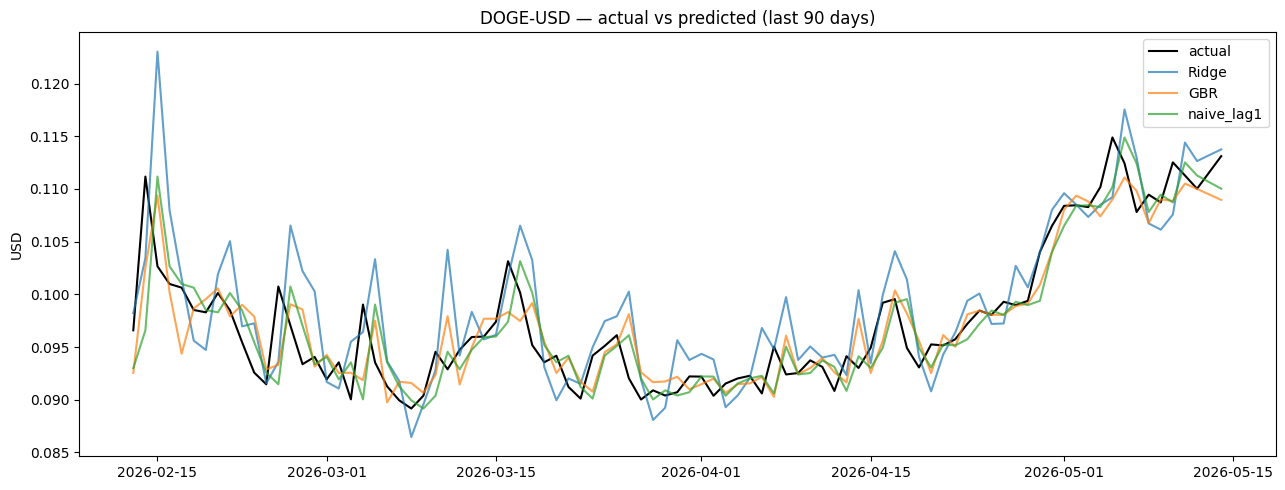

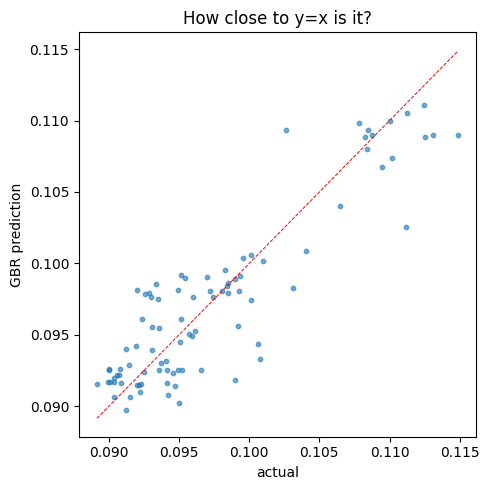

In [5]:
plt.figure(figsize=(13, 5))
plt.plot(y_test.index, y_test.values, label="actual", color="black", linewidth=1.5)
for name, r in results.items():
    plt.plot(y_test.index, r["pred"], label=name, alpha=0.7)
plt.title("DOGE-USD — actual vs predicted (last 90 days)")
plt.ylabel("USD")
plt.legend()
plt.tight_layout()
plt.show()

# also: a scatter of pred vs actual for the GBR. If it's a 45-degree line it's just lag-1.
plt.figure(figsize=(5, 5))
plt.scatter(y_test, results["GBR"]["pred"], alpha=0.6, s=10)
lo, hi = y_test.min(), y_test.max()
plt.plot([lo, hi], [lo, hi], "r--", linewidth=0.7)
plt.xlabel("actual")
plt.ylabel("GBR prediction")
plt.title("How close to y=x is it?")
plt.tight_layout()
plt.show()


## Verdict

DOGE moves on Elon Musk tweets and Reddit threads — features I don't have. The lag-feature regression is essentially fitting "yesterday plus a small drift", which is exactly what you'd expect from a near-random-walk asset.

What would actually move the needle on this problem:
- A Twitter/X sentiment feed keyed on `$DOGE` and `dogecoin`, lagged 4-12 hours
- Reddit post velocity on `r/dogecoin` and `r/cryptocurrency`
- News-event flags (exchange listings, payment-rail announcements)

None of that is happening in this notebook. The right read on the table above is: the models are roughly tied with naive lag-1, which is the honest answer.
